# Training & Evaluasi YOLOv8n — Versi 2 (Hyperparameter Tuning + LR Warmup)



## 1. Mount Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Cek Ketersediaan GPU



In [ ]:
!nvidia-smi


Sat Jul 18 15:28:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             43W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 3. Install & Import Library


In [ ]:
!pip install ultralytics -q

import os
import glob
import time
import random
import shutil

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import ultralytics
from ultralytics import YOLO

ultralytics.checks()


Ultralytics 8.4.100 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 46.7/235.7 GB disk)


## 4. Menentukan Path Dataset di Google Drive

Sesuaikan `DATASET_DIR` dengan lokasi folder dataset Anda di Google Drive.


In [ ]:

DATASET_DIR = '/content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO'

TRAIN_DIR = os.path.join(DATASET_DIR, 'train')
VALID_DIR = os.path.join(DATASET_DIR, 'valid')
TEST_DIR  = os.path.join(DATASET_DIR, 'test')

# Folder khusus untuk hasil eksperimen versi 2 (dipisah dari versi 1 / YOLOv8s)
PROJECT_DIR = os.path.join(DATASET_DIR, 'runs_yolov8n_optimaze')
os.makedirs(PROJECT_DIR, exist_ok=True)

CLASS_NAMES = ['person', 'table']

# Parameter augmentasi bawaan YOLOv8 yang dimatikan
DISABLED_AUG = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0,
    mosaic=0.0, mixup=0.0, copy_paste=0.0, erasing=0.0,
    auto_augment=None,
)

print("Isi folder dataset:")
for item in sorted(os.listdir(DATASET_DIR)):
    print(' -', item)


Isi folder dataset:
 - README.dataset.txt
 - README.roboflow.txt
 - runs_yolov8n_optimaze
 - saved_models
 - test
 - train
 - valid


## 5. Verifikasi Jumlah Data per Split


In [ ]:
splits = {'train': TRAIN_DIR, 'valid': VALID_DIR, 'test': TEST_DIR}
expected = {'train': 1050, 'valid': 100, 'test': 50}

for split_name, split_dir in splits.items():
    img_dir = os.path.join(split_dir, 'images')
    lbl_dir = os.path.join(split_dir, 'labels')
    n_img = len(glob.glob(os.path.join(img_dir, '*.*')))
    n_lbl = len(glob.glob(os.path.join(lbl_dir, '*.txt')))
    status = 'OK' if n_img == expected[split_name] else 'PERIKSA KEMBALI'
    print(f"{split_name:6s}: {n_img} gambar, {n_lbl} label  (ekspektasi: {expected[split_name]})  -> {status}")


train : 1050 gambar, 1050 label  (ekspektasi: 1050)  -> OK
valid : 100 gambar, 100 label  (ekspektasi: 100)  -> OK
test  : 50 gambar, 50 label  (ekspektasi: 50)  -> OK


## 6. Memeriksa / Membuat File `data.yaml`


In [ ]:
data_yaml_path = os.path.join(DATASET_DIR, 'data.yaml')

if os.path.exists(data_yaml_path):
    with open(data_yaml_path, 'r') as f:
        data_config = yaml.safe_load(f) or {}
else:
    data_config = {}

data_config['train'] = os.path.join(TRAIN_DIR, 'images')
data_config['val']   = os.path.join(VALID_DIR, 'images')
data_config['test']  = os.path.join(TEST_DIR, 'images')
data_config['nc']    = len(CLASS_NAMES)
data_config['names'] = CLASS_NAMES

with open(data_yaml_path, 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False)

print("data.yaml:")
print(yaml.dump(data_config, default_flow_style=False))


data.yaml:
names:
- person
- table
nc: 2
test: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/test/images
train: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/train/images
val: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/valid/images



## 7. Visualisasi Contoh Data Training (Sanity Check)


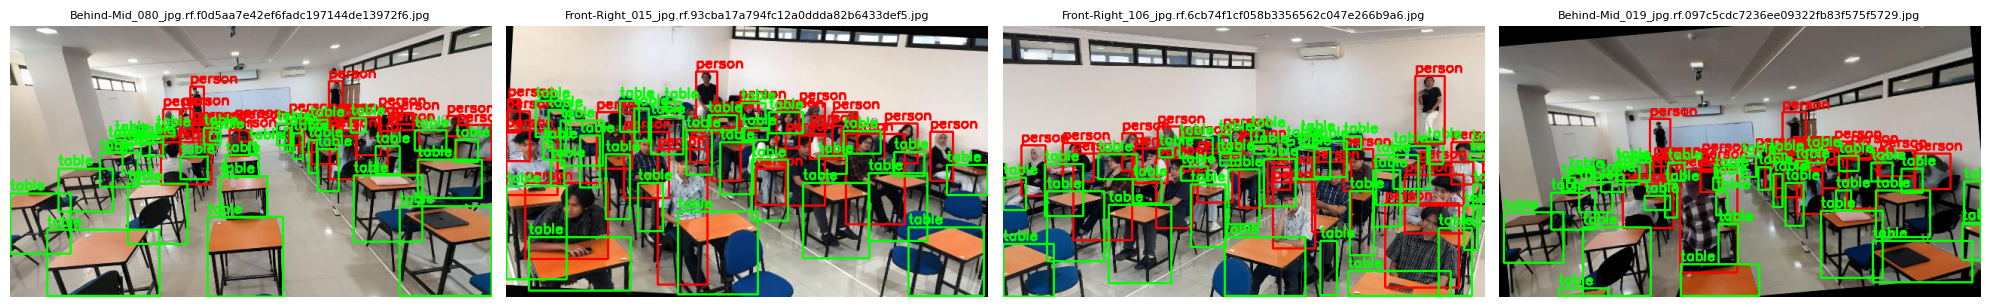

In [ ]:
def draw_yolo_boxes(image_path, label_path, class_names):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f.readlines():
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:5])
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                color = (255, 0, 0) if cls_id == 0 else (0, 255, 0)
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, class_names[cls_id], (x1, max(y1 - 5, 0)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return img

train_img_dir = os.path.join(TRAIN_DIR, 'images')
train_lbl_dir = os.path.join(TRAIN_DIR, 'labels')
sample_files = random.sample(os.listdir(train_img_dir), 4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, fname in zip(axes, sample_files):
    img_path = os.path.join(train_img_dir, fname)
    lbl_path = os.path.join(train_lbl_dir, os.path.splitext(fname)[0] + '.txt')
    img = draw_yolo_boxes(img_path, lbl_path, CLASS_NAMES)
    ax.imshow(img)
    ax.set_title(fname, fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 8. Load Model YOLOv8n Pretrained

Menggunakan **YOLOv8n** (varian nano — paling ringan dan cepat di keluarga YOLOv8), dengan bobot pretrained COCO sebagai titik awal transfer learning.


In [ ]:
MODEL_VARIANT = 'yolov8n.pt'

model = YOLO(MODEL_VARIANT)


## 9. Optimasi 1: Hyperparameter Tuning Otomatis



In [ ]:
RUN_HYPERPARAMETER_TUNING = True  # ubah ke True untuk menjalankan tuning otomatis (BUTUH WAKTU LAMA)

tuned_hyp_path = None

if RUN_HYPERPARAMETER_TUNING:
    tune_model = YOLO(MODEL_VARIANT)
    tune_model.tune(
        data=data_yaml_path,
        epochs=20,
        iterations=30,
        imgsz=640,
        optimizer='AdamW',
        project=PROJECT_DIR,
        name='yolov8n_tune',
        plots=False,
        save=False,
        val=True,
    )
    tuned_hyp_path = os.path.join(PROJECT_DIR, 'yolov8n_tune', 'best_hyperparameters.yaml')
    print("Hyperparameter terbaik disimpan di:", tuned_hyp_path)
else:
    print("Hyperparameter tuning dilewati (RUN_HYPERPARAMETER_TUNING=False). Training final memakai hyperparameter default Ultralytics + LR Warmup manual (Cell 10).")

best_hyp = {}
if tuned_hyp_path and os.path.exists(tuned_hyp_path):
    with open(tuned_hyp_path, 'r') as f:
        best_hyp = yaml.safe_load(f) or {}
    print("\nHyperparameter hasil tuning:")
    print(yaml.dump(best_hyp, default_flow_style=False))


Tuner: Initialized Tuner instance with 'tune_dir=/content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/runs_yolov8n_optimaze/yolov8n_tune'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/30 with hyperparameters: {'lr0': 0.01, 'lrf': 0.01, 'momentum': 0.937, 'weight_decay': 0.0005, 'warmup_epochs': 3.0, 'warmup_momentum': 0.8, 'box': 7.5, 'cls': 0.5, 'cls_pw': 0.0, 'dfl': 1.5, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'degrees': 0.0, 'translate': 0.1, 'scale': 0.5, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.0, 'fliplr': 0.5, 'bgr': 0.0, 'mosaic': 1.0, 'mixup': 0.0, 'cutmix': 0.0, 'copy_paste': 0.0, 'close_mosaic': 10}
Saved /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/runs_yolov8n_optimaze/yolov8n_tune/tune_scatter_plots.png
Saved /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/runs_yolov8n_optimaze/yolov8n_tune/tune_fitness.png

Tuner: 1/30 iterations complete ✅ (173.14s)
Tuner: Results

## 10. Optimasi 2: LR Warmup



In [ ]:
WARMUP_EPOCHS = 5.0
WARMUP_MOMENTUM = 0.8   # nilai default Ultralytics, umumnya sudah baik
WARMUP_BIAS_LR = 0.1    # nilai default Ultralytics

FIXED_WARMUP = dict(
    warmup_epochs=WARMUP_EPOCHS,
    warmup_momentum=WARMUP_MOMENTUM,
    warmup_bias_lr=WARMUP_BIAS_LR,
)

# Hyperparameter hasil tuning dipakai untuk training final, KECUALI untuk key augmentasi
# (selalu 0) dan key warmup (selalu pakai nilai manual FIXED_WARMUP di atas)
EXCLUDE_FROM_TUNE_OVERRIDE = set(DISABLED_AUG.keys()) | set(FIXED_WARMUP.keys())
best_hyp_non_aug = {k: v for k, v in best_hyp.items() if k not in EXCLUDE_FROM_TUNE_OVERRIDE}

print("LR Warmup yang dipakai:", FIXED_WARMUP)
print("\nHyperparameter tambahan dari tuning (di luar augmentasi & warmup):", best_hyp_non_aug)


LR Warmup yang dipakai: {'warmup_epochs': 5.0, 'warmup_momentum': 0.8, 'warmup_bias_lr': 0.1}

Hyperparameter tambahan dari tuning (di luar augmentasi & warmup): {'lr0': 0.00766, 'lrf': 0.01, 'momentum': 0.91911, 'weight_decay': 0.00098, 'box': 5.84059, 'cls': 0.42361, 'cls_pw': 0.0029, 'dfl': 1.00795, 'bgr': 0.00555, 'cutmix': 0.0, 'close_mosaic': 8}


## 11. Training Model Final (YOLOv8n + Hyperparameter Tuning + LR Warmup)



In [ ]:
start_time = time.time()

results = model.train(
    data=data_yaml_path,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=50,
    optimizer="AdamW",
    cos_lr=True,
    project=PROJECT_DIR,
    name="yolov8n_classroom_optimaze2",
    exist_ok=True,
    verbose=True,
    **DISABLED_AUG,
    **best_hyp_non_aug,
    **FIXED_WARMUP,
)

training_time = time.time() - start_time
print(f"\nTotal waktu training: {training_time/60:.2f} menit")

Ultralytics 8.4.100 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.00555, box=5.84059, cache=False, cfg=None, classes=None, close_mosaic=8, cls=0.42361, cls_pw=0.0029, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.00795, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00766, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.91911, mosaic=0.0, multi_scale=0.0, name=yolov8n_classroom_op

## 12. Kurva Training (Sanity Check)


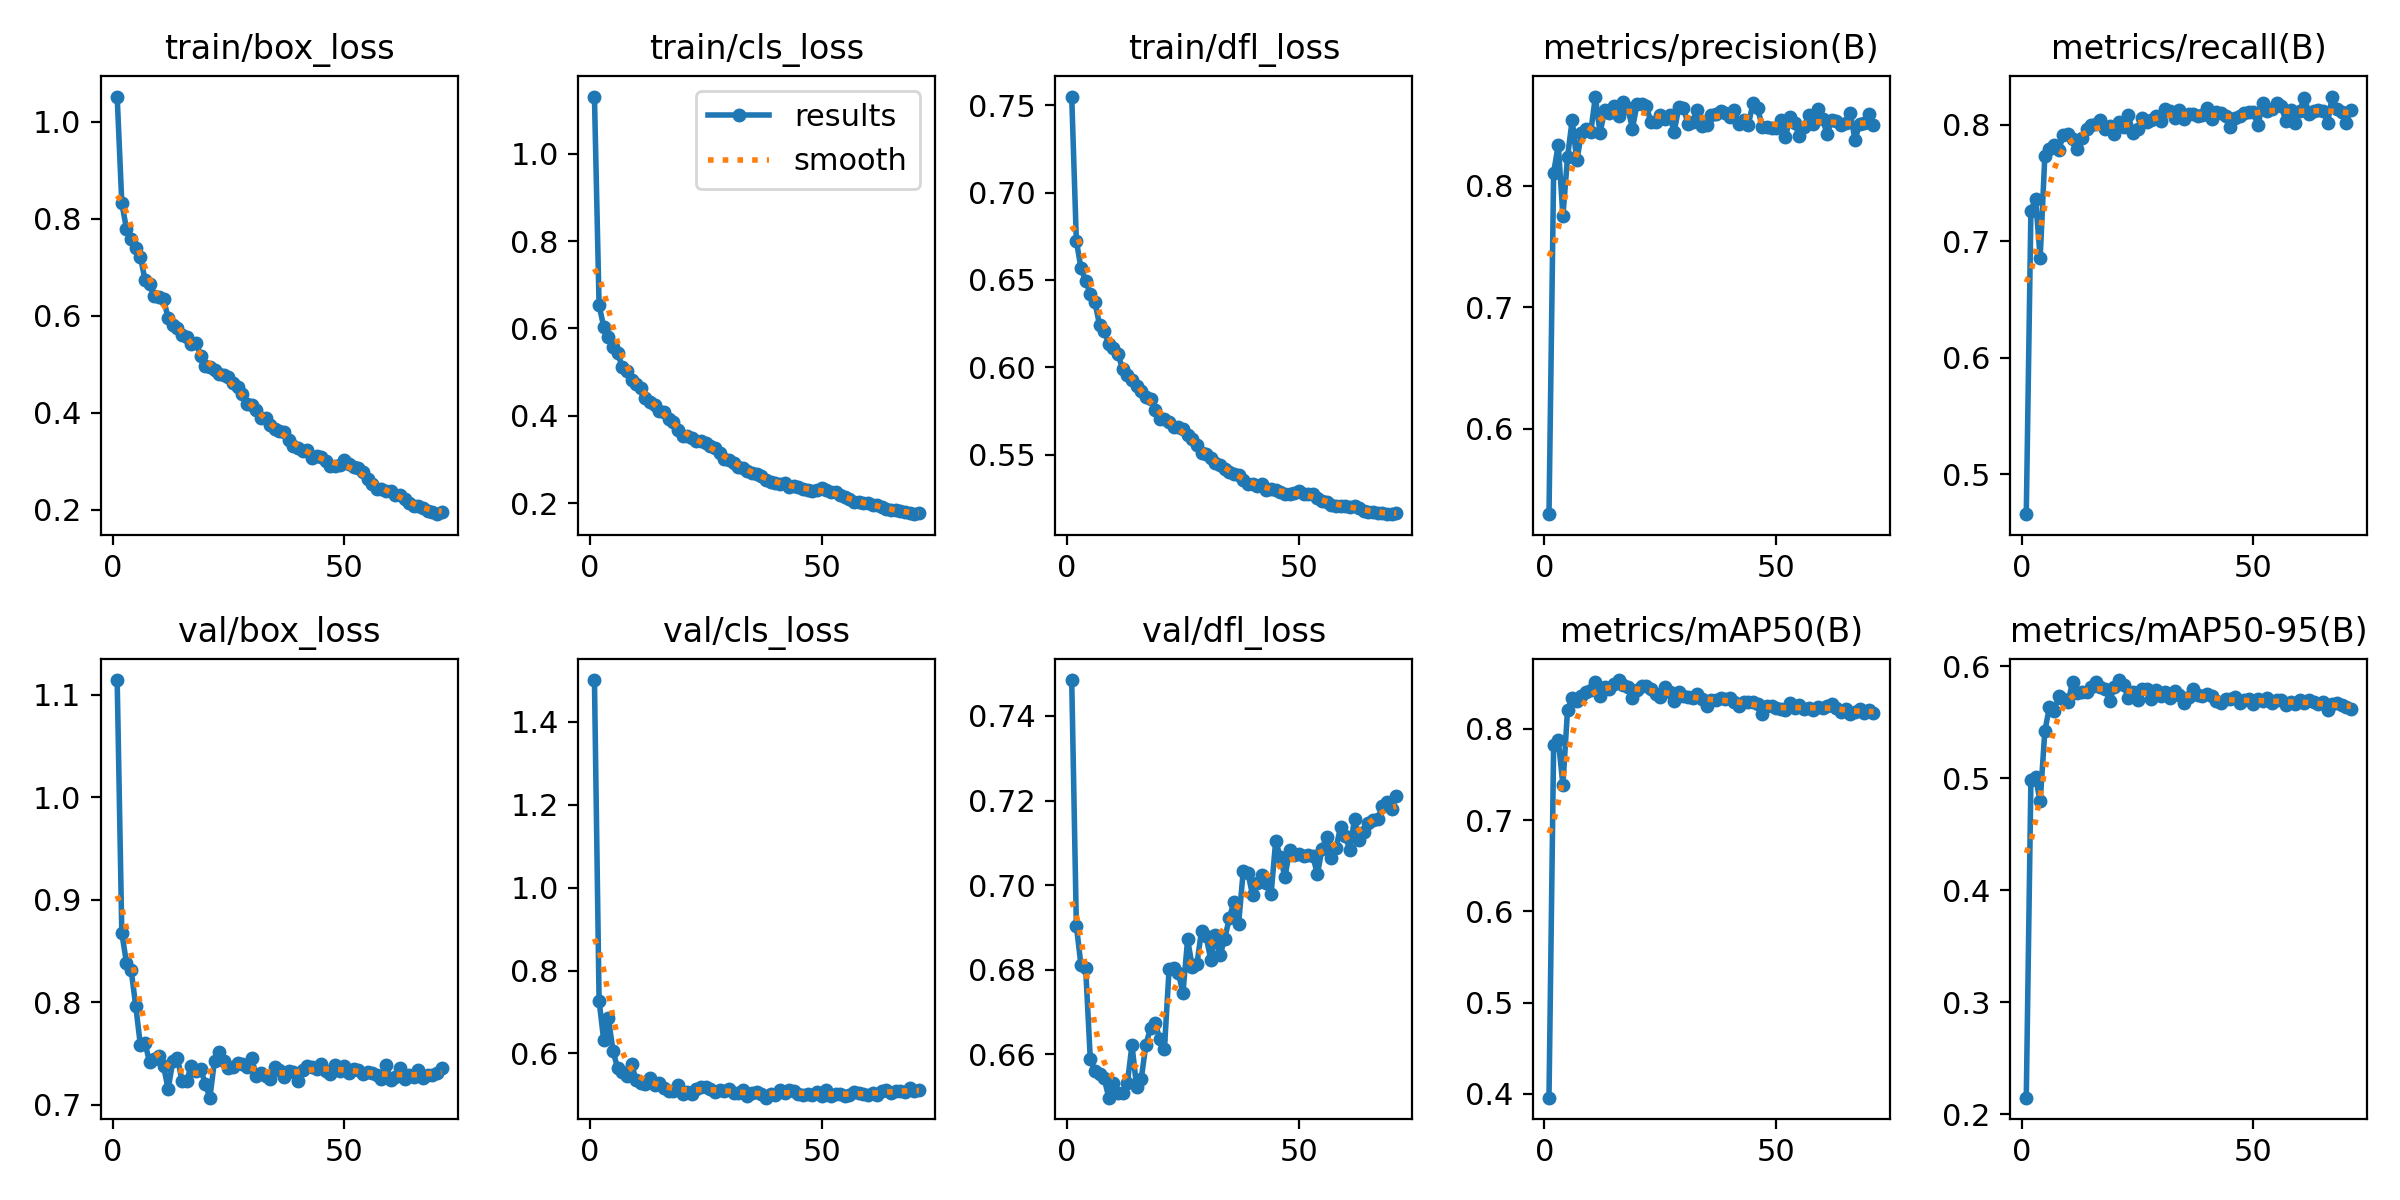

In [ ]:
run_dir = os.path.join(PROJECT_DIR, 'yolov8n_classroom_optimaze2')
display(Image(filename=os.path.join(run_dir, 'results.png')))


## 13. Load Model Terbaik


In [ ]:
best_model_path = os.path.join(run_dir, 'weights', 'best.pt')
best_model = YOLO(best_model_path)
print("Model terbaik dimuat dari:", best_model_path)


Model terbaik dimuat dari: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/runs_yolov8n_optimaze/yolov8n_classroom_optimaze2/weights/best.pt


## 14. Evaluasi Test Set — mAP@50

Sesuai kebutuhan versi ini, evaluasi difokuskan pada **mAP@50 saja** (tanpa mAP@50-95).


In [ ]:
# ==========================================================
# Evaluasi Model YOLOv8 pada Test Set
# Menampilkan Precision, Recall, mAP@50, dan mAP@50-95
# ==========================================================

metrics_test = best_model.val(
    data=data_yaml_path,
    split="test",
    imgsz=640,
    project=PROJECT_DIR,
    name="yolov8n_val_test",
    exist_ok=True,
)

print("=" * 55)
print("           HASIL EVALUASI TEST SET")
print("=" * 55)

print(f"Precision (mP) : {metrics_test.box.mp:.4f}")
print(f"Recall (mR)    : {metrics_test.box.mr:.4f}")
print(f"mAP@50         : {metrics_test.box.map50:.4f}")
print(f"mAP@50-95      : {metrics_test.box.map:.4f}")

print("\n" + "=" * 55)
print("              HASIL PER KELAS")
print("=" * 55)

try:
    for i, cls_name in enumerate(CLASS_NAMES):
        print(f"\nKelas : {cls_name}")
        print(f"  mAP@50      : {metrics_test.box.ap50[i]:.4f}")
        print(f"  mAP@50-95   : {metrics_test.box.maps[i]:.4f}")
except Exception:
    print("mAP per kelas tidak tersedia pada versi Ultralytics yang digunakan.")

print("\n" + "=" * 55)
print("Evaluasi selesai.")
print("=" * 55)

Ultralytics 8.4.100 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 0.2±0.0 MB/s, size: 40.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/test/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 15.0Mit/s 0.0s
val: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/test/images/Front-Left_065_jpg.rf.35e94b463fca34d909542195ea428cd0.jpg: 2 duplicate labels removed
val: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/test/images/Front-Mid_030_jpg.rf.3fd256f6907f31dfefb0136576dff047.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/test/images/Front-Mid_053_jpg.rf.

## 15. Confusion Matrix

Diambil dari `save_dir` hasil evaluasi test set (`metrics_test`) di Cell 14.


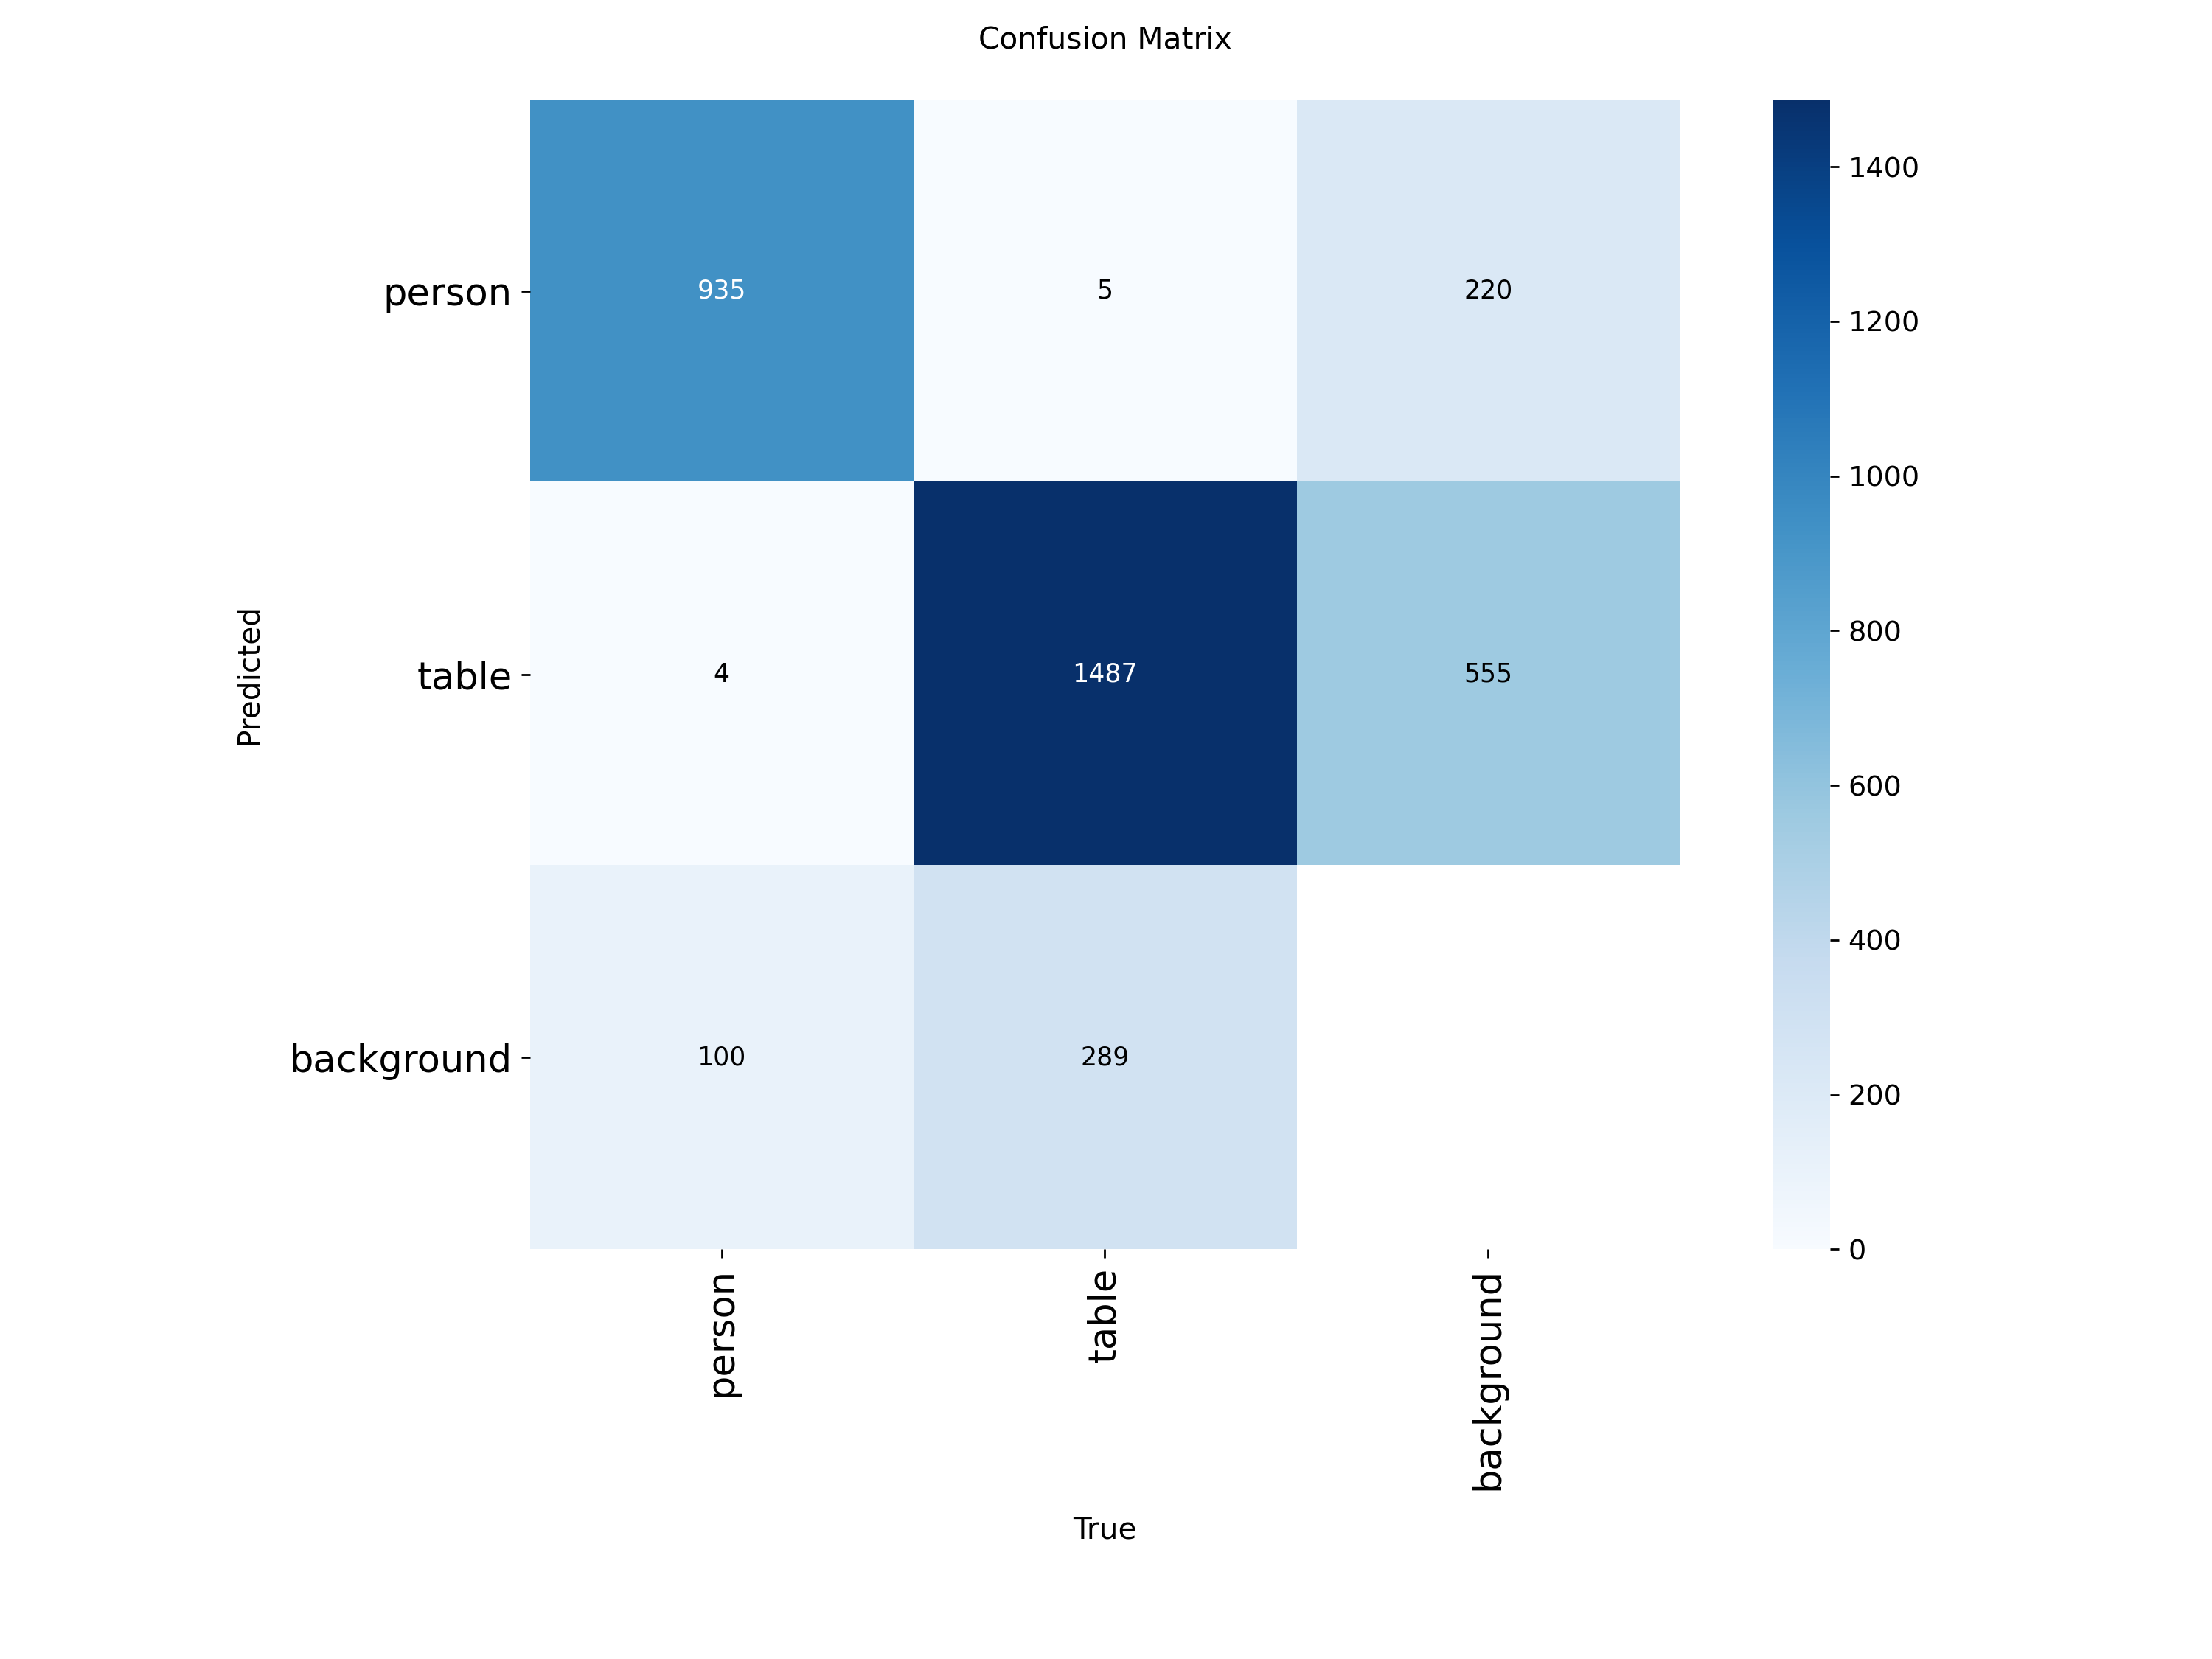

In [ ]:
cm_path = os.path.join(str(metrics_test.save_dir), 'confusion_matrix.png')
display(Image(filename=cm_path))


## 16. FPS (Kecepatan Inferensi)

Menggunakan threshold confidence & IoU default Ultralytics (conf=0.25, iou=0.7), karena versi notebook ini tidak memakai tahap threshold tuning.


In [ ]:
test_img_dir = os.path.join(TEST_DIR, 'images')
image_files = sorted(glob.glob(os.path.join(test_img_dir, '*.*')))
sample_imgs = image_files[:30] if len(image_files) >= 30 else image_files

CONF_THRESHOLD = 0.3
IOU_THRESHOLD = 0.5

# Warm-up
_ = best_model.predict(sample_imgs[0], conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, verbose=False)

times = []
for img_path in sample_imgs:
    start = time.time()
    _ = best_model.predict(img_path, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, verbose=False)
    times.append(time.time() - start)

avg_time = np.mean(times)
fps = 1 / avg_time

print(f"Rata-rata waktu inferensi : {avg_time * 1000:.2f} ms/gambar")
print(f"FPS                       : {fps:.2f}")


Rata-rata waktu inferensi : 14.04 ms/gambar
FPS                       : 71.23


## 17. Object Counting — MAE



In [ ]:
def count_ground_truth(label_path, class_names):
    counts = {name: 0 for name in class_names}
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f.readlines():
                line = line.strip()
                if not line:
                    continue
                cls_id = int(line.split()[0])
                counts[class_names[cls_id]] += 1
    return counts

test_labels_dir = os.path.join(TEST_DIR, 'labels')

results_list = []
for img_path in image_files:
    filename = os.path.basename(img_path)
    label_path = os.path.join(test_labels_dir, os.path.splitext(filename)[0] + '.txt')

    gt_counts = count_ground_truth(label_path, CLASS_NAMES)

    pred = best_model.predict(img_path, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, verbose=False)[0]
    pred_counts = {name: 0 for name in CLASS_NAMES}
    for box in pred.boxes:
        cls_id = int(box.cls[0])
        pred_counts[CLASS_NAMES[cls_id]] += 1

    row = {'filename': filename}
    for name in CLASS_NAMES:
        row[f'gt_{name}'] = gt_counts[name]
        row[f'pred_{name}'] = pred_counts[name]
    results_list.append(row)

df_counting = pd.DataFrame(results_list)

print("=== MAE Counting per Kelas ===")
mae_rows = []
for name in CLASS_NAMES:
    gt = df_counting[f'gt_{name}']
    pred = df_counting[f'pred_{name}']
    mae = np.mean(np.abs(gt - pred))
    mae_rows.append({'class': name, 'MAE': mae})
    print(f"Kelas '{name}': MAE = {mae:.3f}")

df_mae_summary = pd.DataFrame(mae_rows)

df_counting.to_csv(os.path.join(PROJECT_DIR, 'counting_results_yolov8n_v2_per_image.csv'), index=False)
df_mae_summary.to_csv(os.path.join(PROJECT_DIR, 'counting_results_yolov8n_v2_mae_summary.csv'), index=False)

df_mae_summary


=== MAE Counting per Kelas ===
Kelas 'person': MAE = 1.220
Kelas 'table': MAE = 2.820


,class,MAE
0,person,1.22
1,table,2.82


## 17B. Simulasi Counting dengan Visualisasi


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

# ============================================================
# FALLBACK KONFIGURASI
# ============================================================
try:
    CONF_THRESHOLD, IOU_THRESHOLD
except NameError:
    CONF_THRESHOLD, IOU_THRESHOLD = 0.30, 0.50

try:
    test_img_dir, test_labels_dir
except NameError:
    test_img_dir = os.path.join(TEST_DIR, 'images')
    test_labels_dir = os.path.join(TEST_DIR, 'labels')

try:
    count_ground_truth
except NameError:
    def count_ground_truth(label_path, class_names):
        counts = {name: 0 for name in class_names}

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f:
                    line = line.strip()

                    if not line:
                        continue

                    cls_id = int(line.split()[0])

                    if 0 <= cls_id < len(class_names):
                        counts[class_names[cls_id]] += 1

        return counts


# ============================================================
# FUNGSI VISUALISASI PREDIKSI
# ============================================================
def simulate_counting_visual(
    model,
    img_path,
    label_path,
    class_names,
    conf,
    iou
):

    # Baca gambar
    img_bgr = cv2.imread(img_path)

    if img_bgr is None:
        raise ValueError(f"Gambar tidak dapat dibaca: {img_path}")

    img_original = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    # Salinan gambar untuk hasil prediksi
    img_pred = img_original.copy()

    h, w = img_pred.shape[:2]

    # ========================================================
    # HITUNG GROUND TRUTH
    # ========================================================
    gt_counts = count_ground_truth(
        label_path,
        class_names
    )

    # ========================================================
    # PREDIKSI MODEL
    # ========================================================
    result = model.predict(
        img_path,
        conf=conf,
        iou=iou,
        verbose=False
    )[0]

    pred_counts = {
        name: 0
        for name in class_names
    }

    # Warna bounding box
    colors = {
        'table': (255, 80, 80),
        'person': (80, 200, 80)
    }

    # ========================================================
    # GAMBAR BOUNDING BOX DAN LABEL
    # ========================================================
    for box in result.boxes:

        cls_id = int(box.cls[0])

        if cls_id >= len(class_names):
            continue

        cls_name = class_names[cls_id]

        pred_counts[cls_name] += 1

        # Koordinat bounding box
        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].cpu().numpy()
        )

        conf_score = float(box.conf[0])

        color = colors.get(
            cls_name,
            (255, 255, 0)
        )

        # ====================================================
        # BOUNDING BOX TIPIS
        # ====================================================
        cv2.rectangle(
            img_pred,
            (x1, y1),
            (x2, y2),
            color,
            1
        )

        # ====================================================
        # LABEL KECIL TANPA BACKGROUND
        # ====================================================
        label_text = f"{cls_name} {conf_score:.2f}"

        font_scale = 0.25
        font_thickness = 1

        (tw, th), baseline = cv2.getTextSize(
            label_text,
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            font_thickness
        )

        # Posisi label di atas bounding box
        text_x = x1
        text_y = y1 - 3

        # Jika terlalu dekat dengan batas atas
        if text_y - th < 0:
            text_y = y1 + th + 3

        # Jika keluar dari sisi kanan
        if text_x + tw > w:
            text_x = max(0, w - tw - 2)

        # Tulis label tanpa background
        cv2.putText(
            img_pred,
            label_text,
            (text_x, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            color,
            font_thickness,
            cv2.LINE_AA
        )

    return (
        img_pred,
        img_original,
        gt_counts,
        pred_counts
    )


# ============================================================
# PILIH 4 GAMBAR TEST SECARA ACAK
# ============================================================
N_SIMULASI = 4

valid_extensions = (
    '.jpg',
    '.jpeg',
    '.png',
    '.bmp'
)

all_test_files = [
    f for f in os.listdir(test_img_dir)
    if f.lower().endswith(valid_extensions)
]

sim_files = random.sample(
    all_test_files,
    min(N_SIMULASI, len(all_test_files))
)


# ============================================================
# SIAPKAN FIGURE
#
# BARIS 1 = HASIL PREDIKSI
# TENGAH   = INFORMASI SELISIH
# BARIS 2 = GAMBAR ASLI / GROUND TRUTH
# ============================================================

# Tinggi figure diperkecil agar ruang putih tidak terlalu besar
fig, axes = plt.subplots(
    2,
    4,
    figsize=(24, 8)
)

# Perkecil jarak horizontal dan vertikal antar gambar
plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.90,
    bottom=0.03,
    wspace=0.02,
    hspace=0.28
)


# ============================================================
# INISIALISASI TOTAL COUNTING
# ============================================================
all_gt = {
    name: 0
    for name in CLASS_NAMES
}

all_pred = {
    name: 0
    for name in CLASS_NAMES
}


# ============================================================
# PROSES SETIAP GAMBAR
# ============================================================
for i, fname in enumerate(sim_files):

    img_path = os.path.join(
        test_img_dir,
        fname
    )

    label_path = os.path.join(
        test_labels_dir,
        os.path.splitext(fname)[0] + '.txt'
    )

    (
        vis_img,
        original_img,
        gt_counts,
        pred_counts
    ) = simulate_counting_visual(
        best_model,
        img_path,
        label_path,
        CLASS_NAMES,
        CONF_THRESHOLD,
        IOU_THRESHOLD
    )

    # ========================================================
    # AKUMULASI COUNTING
    # ========================================================
    for name in CLASS_NAMES:
        all_gt[name] += gt_counts[name]
        all_pred[name] += pred_counts[name]


    # ========================================================
    # HITUNG SELISIH PER GAMBAR
    # ========================================================
    differences = {
        name: abs(
            gt_counts[name] - pred_counts[name]
        )
        for name in CLASS_NAMES
    }


    # ========================================================
    # BARIS PERTAMA
    # HASIL PREDIKSI
    # ========================================================
    axes[0, i].imshow(vis_img)

    counting_text = " | ".join(
        [
            f"{name}: {pred_counts[name]}"
            for name in CLASS_NAMES
        ]
    )

    axes[0, i].set_title(
        f"Hasil Prediksi\n{counting_text}",
        fontsize=10,
        fontweight='bold',
        pad=3
    )

    axes[0, i].axis('off')


    # ========================================================
    # BARIS KEDUA
    # GAMBAR ASLI / GROUND TRUTH
    # ========================================================
    axes[1, i].imshow(original_img)

    gt_text = " | ".join(
        [
            f"{name}: {gt_counts[name]}"
            for name in CLASS_NAMES
        ]
    )

    axes[1, i].set_title(
        f"Gambar Asli / Ground Truth\n{gt_text}",
        fontsize=10,
        pad=3
    )

    axes[1, i].axis('off')


    # ========================================================
    # INFORMASI SELISIH DI ANTARA DUA BARIS GAMBAR
    # ========================================================
    diff_text = " | ".join(
        [
            f"Selisih {name}: {differences[name]}"
            for name in CLASS_NAMES
        ]
    )

    # Ambil posisi gambar baris atas dan bawah
    top_pos = axes[0, i].get_position()
    bottom_pos = axes[1, i].get_position()

    # Posisi tengah antara gambar prediksi dan gambar asli
    center_x = (
        top_pos.x0 + top_pos.x1
    ) / 2

    center_y = (
        top_pos.y0 + bottom_pos.y1
    ) / 2

    # Tampilkan informasi selisih
    fig.text(
        center_x,
        center_y,
        diff_text,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold'
    )


# ============================================================
# MATIKAN AXIS JIKA GAMBAR KURANG DARI 4
# ============================================================
for i in range(len(sim_files), 4):
    axes[0, i].axis('off')
    axes[1, i].axis('off')


# ============================================================
# JUDUL UTAMA
# ============================================================
fig.suptitle(
    "Perbandingan Hasil Object Counting dengan Ground Truth",
    fontsize=15,
    fontweight='bold',
    y=0.97
)


# ============================================================
# TAMPILKAN HASIL
# ============================================================
plt.show()


# ============================================================
# RINGKASAN SIMULASI COUNTING
# ============================================================
print("\n========================================")
print("RINGKASAN SIMULASI OBJECT COUNTING")
print("========================================")

for name in CLASS_NAMES:

    diff = abs(
        all_gt[name] - all_pred[name]
    )

    print(
        f"{name:8s}: "
        f"Ground Truth = {all_gt[name]:3d} | "
        f"Prediksi = {all_pred[name]:3d} | "
        f"Selisih = {diff}"
    )

Output hidden; open in https://colab.research.google.com to view.

## 18. GFLOPs & Jumlah Parameter


In [ ]:
info_result = best_model.info(detailed=False, verbose=True)

try:
    n_layers, n_params, n_gradients, gflops = info_result
    print(f"\nJumlah layer     : {n_layers}")
    print(f"Jumlah parameter : {n_params:,}")
    print(f"GFLOPs           : {gflops:.2f}")
except (TypeError, ValueError):
    # Fallback jika versi Ultralytics tidak mengembalikan tuple dari .info()
    n_params = sum(p.numel() for p in best_model.model.parameters())
    from ultralytics.utils.torch_utils import get_flops
    gflops = get_flops(best_model.model, imgsz=640)
    print(f"\nJumlah parameter : {n_params:,}")
    print(f"GFLOPs           : {gflops:.2f}")


Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs

Jumlah layer     : 73
Jumlah parameter : 3,006,038
GFLOPs           : 8.09


## 19. Menyimpan Model ke Google Drive


In [ ]:
backup_dir = os.path.join(DATASET_DIR, 'saved_models')
os.makedirs(backup_dir, exist_ok=True)

backup_path = os.path.join(backup_dir, 'yolov8n_v2_hptuning_lrwarmup_best.pt')
shutil.copy(best_model_path, backup_path)

print("Model tersimpan di:", backup_path)


Model tersimpan di: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas YOLO/saved_models/yolov8n_v2_hptuning_lrwarmup_best.pt


## 20. Ringkasan Hasil — Versi 2 (YOLOv8n + Hyperparameter Tuning + LR Warmup)

| Metrik | Hasil |
|---|---|
| Model | YOLOv8n |
| Optimasi | Hyperparameter Tuning (`RUN_HYPERPARAMETER_TUNING`), LR Warmup (`warmup_epochs=5.0`) |
| mAP@50 (test set) | lihat Cell 14 |
| FPS | lihat Cell 16 |
| MAE Counting (table / person) | lihat Cell 17 |
| GFLOPs | lihat Cell 18 |
| Jumlah Parameter | lihat Cell 18 |
| Total waktu training | lihat Cell 11 |

Gunakan tabel ini sebagai salah satu baris pembanding dalam tabel *ablation study* / perbandingan konfigurasi di bab hasil skripsi Anda, disandingkan dengan versi YOLOv8s baseline dan hasil EfficientDet.
